<a href="https://colab.research.google.com/github/florence-aikins/credit-card-fraud-detection/blob/main/credit_card_fraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_curve,
    f1_score,
    roc_auc_score
)

In [34]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mlg-ulb/creditcardfraud",
  "creditcard.csv"
)
df.head()

/tmp/ipykernel_538/69881442.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'creditcardfraud' dataset.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [35]:
df.shape

(284807, 31)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [37]:
df.duplicated().sum()

np.int64(1081)

In [38]:
df["Class"].value_counts()

,count
Class,
0,284315
1,492


In [39]:
duplicate_rows = df[df.duplicated(keep=False)]
duplicate_rows.value_counts()

Time      V1          V2          V3         V4         V5         V6         V7          V8          V9         V10        V11        V12        V13        V14        V15        V16        V17        V18        V19        V20        V21         V22        V23        V24        V25        V26        V27        V28        Amount  Class
163152.0  -1.196037    1.585949    2.883976   3.378471   1.511706   3.717077   0.585362   -0.156001    0.122648   4.217934   1.385525  -0.709405  -0.256168  -1.564352   1.693218  -0.785210  -0.228008  -0.412833   0.234834   1.375790  -0.370294    0.524395  -0.355170  -0.869790  -0.133198   0.327804  -0.035702  -0.858197  7.56    0        18
          -1.203617    1.574009    2.889277   3.381404   1.538663   3.698747   0.560211   -0.150911    0.124136   4.220998   1.384569  -0.706897  -0.256274  -1.562583   1.692915  -0.787338  -0.226776  -0.412354   0.234322   1.385597  -0.366727    0.522223  -0.357329  -0.870174  -0.134166   0.327019  -0.042648  -0.855262  1.51    0        18
170731.0   2.033492    0.766969   -2.107555   3.631952   1.348594  -0.499907   0.945159   -0.286392   -1.370581   1.653073  -1.600434  -1.510901  -2.143280   1.189850  -0.875588   0.175808  -0.419433  -0.464717  -1.414528  -0.430560   0.241894    0.658545  -0.102644   0.580535   0.643637   0.347240  -0.116618  -0.078601  0.76    0         9
43153.0   -2.086016    2.203265    1.654339   2.941050  -1.683045   0.529728  -1.352162    1.793449   -0.723686   0.600365  -0.982212  -0.551636  -1.337000   0.834403   1.251862   0.033455   1.067978   0.160510   0.213087   0.079002   0.216444    0.567241  -0.035345   0.370201   0.157378   0.440341   0.210230   0.090558  0.76    0         9
68207.0   -13.192671   12.785971  -9.906650   3.320337  -4.801176   5.760059  -18.750889  -37.353443  -0.391540  -5.052502   4.406806  -4.610756  -1.909488  -9.072711  -0.226074  -6.211557  -6.248145  -3.149247   0.051576  -3.493050   27.202839  -8.887017   5.303607  -0.639435   0.263203  -0.108877   1.269566   0.939407  1.00    1         6
                                                                                                                                                                                                                                                                                                                                                    ..
168079.0  -1.544438   -0.281298    1.828622  -1.194474   1.206043   1.256458  -0.280580    0.722871    0.174944  -0.933399   0.708212   0.242038  -1.089207   0.064867   0.009346  -0.172342  -0.110199  -0.613912  -1.519366  -0.149706   0.347237    0.918644  -0.374151  -1.380221   0.421137   0.741332  -0.179012   0.143378  5.45    0         2
167138.0  -1.559594    1.285051   -1.628724  -1.126774  -0.226806  -0.175288   0.748719    0.633820    0.190175  -0.155569  -0.031455   0.324237  -1.120864   0.998667  -0.821482   0.233146  -0.454559   0.237225   0.460647  -0.552728  -0.145031   -0.306385   0.287874   0.248714   0.211528  -0.155660  -0.427796   0.095817  136.73  0         2
          -1.635398    1.165660   -1.575714  -1.097440   0.042763  -0.358590   0.497211    0.684716    0.205058  -0.124929  -0.041008   0.349317  -1.121924   1.016357  -0.824519   0.211873  -0.442234   0.242013   0.455532  -0.454657  -0.109359   -0.328097   0.266280   0.244870   0.201849  -0.163515  -0.497259   0.125172  76.23   0         2
166924.0  -0.890573    1.504586    0.679488   1.246801  -0.462069  -0.009461  -0.077240    0.811214   -0.267707  -0.848571  -1.456434   1.305430   1.164847   0.075157  -1.186711  -0.779921   0.590396  -0.759828   1.135328  -0.252810  -0.293242   -0.791044   0.234858  -0.049781  -0.753883  -1.017529  -0.104500   0.086882  11.70   0         2
26.0      -0.535388    0.865268    1.351076   0.147575   0.433680   0.086983   0.693039    0.179742   -0.285642  -0.482474   0.871800   0.853447  -0.571822   0.102252  -1.519991  -0.285912  -0.309633  -0.403902  -0.823743  -0.283264 

In [40]:
df = df.drop_duplicates()

In [41]:
df.shape

(283726, 31)

In [42]:
df.duplicated().sum()

np.int64(0)

In [43]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


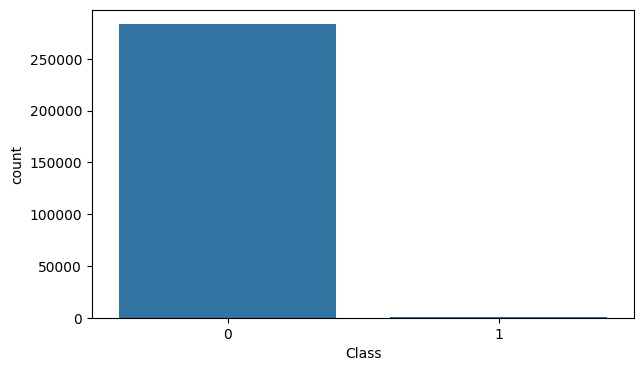

In [44]:
plt.figure(figsize=(7,4))

sns.countplot(data=df, x="Class")
plt.show()

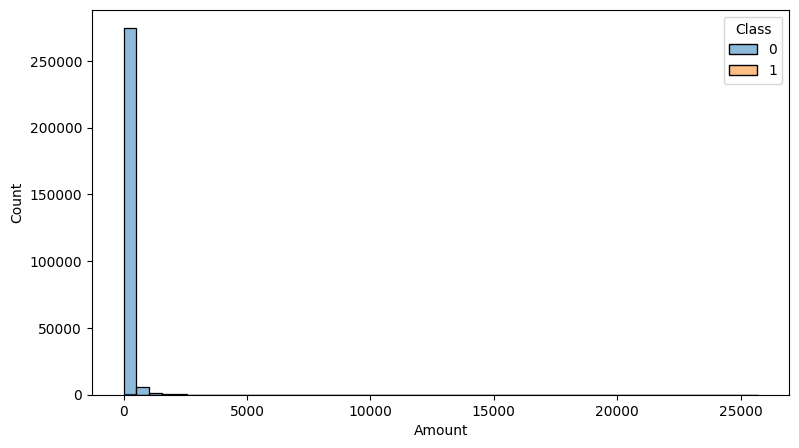

In [45]:
plt.figure(figsize=(9,5))

sns.histplot(data=df, x="Amount", hue="Class", bins=50)
plt.show()

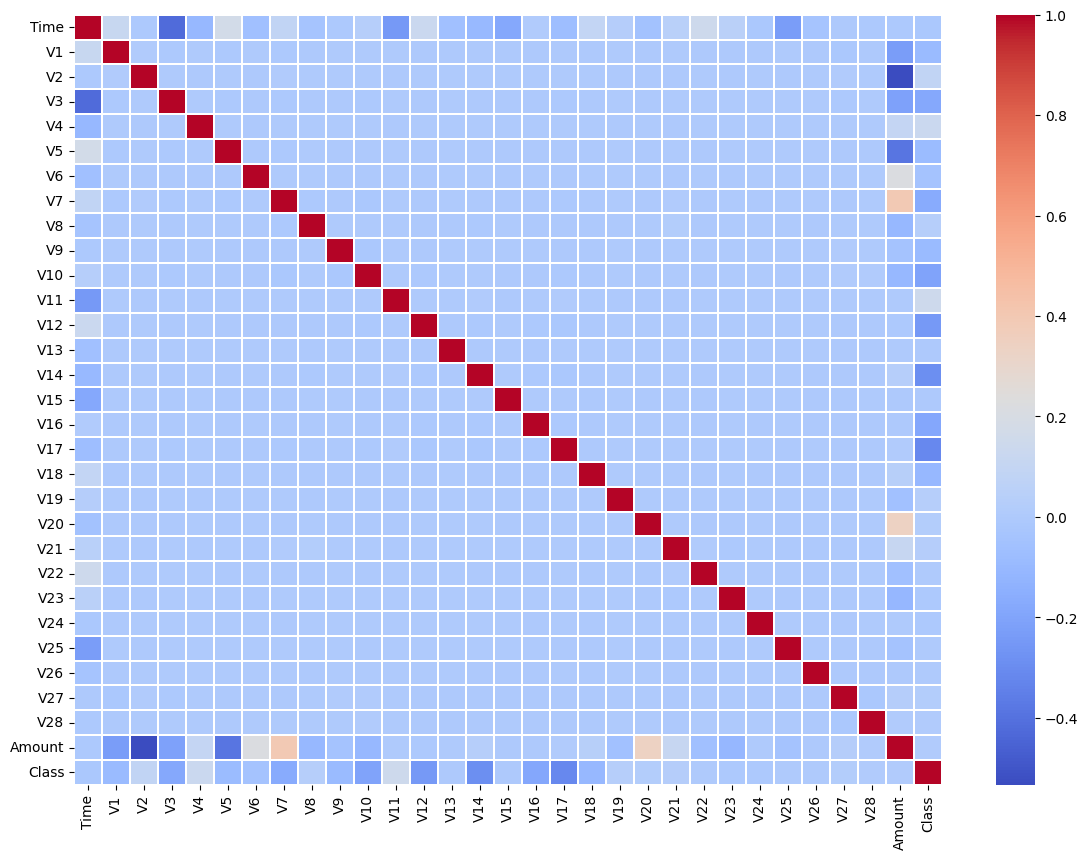

In [46]:
plt.figure(figsize=(14,10))

correlation = df.corr()
sns.heatmap(correlation, cmap="coolwarm", annot=False, linewidths=0.2)
plt.show()

In [47]:
# Calculate correlation with the target variable
class_correlation = df.corr()["Class"].drop("Class")

# Sort correlations by absolute strength
class_correlation = class_correlation.reindex(
    class_correlation.abs().sort_values(ascending=False).index
)

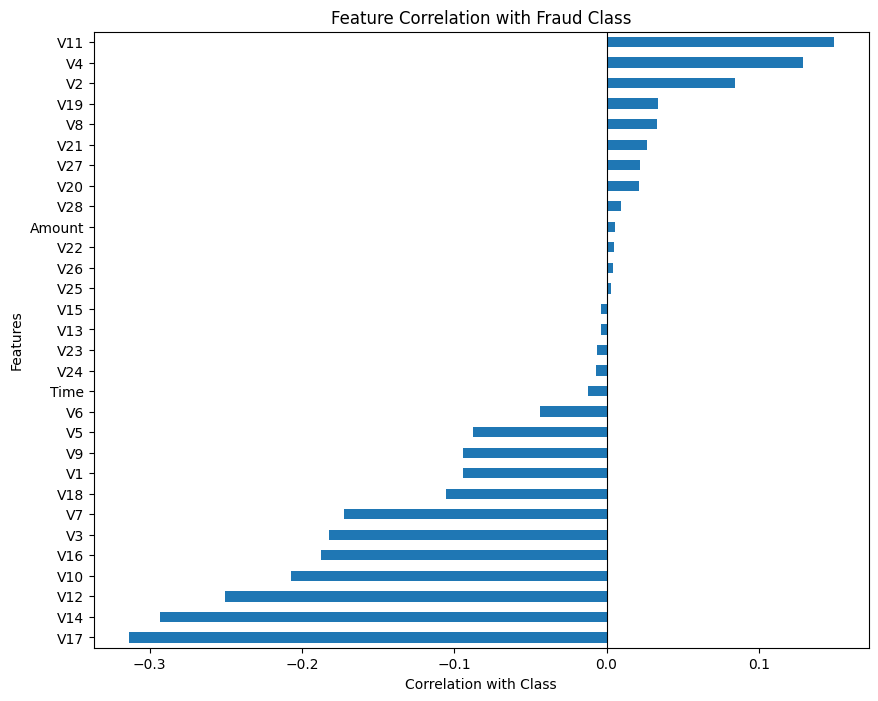

In [48]:
plt.figure(figsize=(10, 8))

class_correlation.sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Fraud Class")
plt.xlabel("Correlation with Class")
plt.ylabel("Features")

plt.axvline(x=0, color="black", linewidth=0.8)

plt.show()

In [49]:
# V17 and V14 have the strongest negative correlations with the fraud target.
# This suggests that these components contain useful information for distinguishing fraudulent transactions from legitimate ones.
# V11, V4 and V2 have positive correlations, suggesting that higher values tend to be associated with fraudulent transactions.

DATA PREPROCESSING

In [50]:
X = df.drop("Class", axis=1)
y = df["Class"]
X.shape, y.shape

((283726, 30), (283726,))

In [51]:
X_train, X_test, y_train, y_test =train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(226980, 30)
(56746, 30)
Class
0    226602
1       378
Name: count, dtype: int64
Class
0    56651
1       95
Name: count, dtype: int64


In [52]:
# Our dataset is highly imbalanced. Stratification ensures that both training and
# testing sets maintain approximately the same proportion of fraudulent and legitimate transactions.

In [53]:
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test_scaled[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])
print(X_train_scaled[["Time", "Amount"]].describe())

               Time        Amount
count  2.269800e+05  2.269800e+05
mean  -1.522636e-16  7.487965e-17
std    1.000002e+00  1.000002e+00
min   -1.998400e+00 -3.596386e-01
25%   -8.561822e-01 -3.364866e-01
50%   -2.123526e-01 -2.697972e-01
75%    9.363191e-01 -4.287453e-02
max    1.640237e+00  7.962087e+01


In [54]:
# we use fit_transform() on the training data but only transform() on the test data.
# This prevents data leakage.
# We are retaining the PCA features without scaling them again in this initial experiment.

In [55]:
# Calculate class weights from training data
legitimate_count = (y_train == 0).sum()
fraudulent_count = (y_train == 1).sum()
scale_pos_weight = legitimate_count/fraudulent_count

print(legitimate_count)
print(fraudulent_count)
print(scale_pos_weight)

226602
378
599.4761904761905


In [56]:
logistic_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

In [57]:
logistic_model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [58]:
y_pred = logistic_model.predict(X_test_scaled)
y_prob = logistic_model.predict_proba(X_test_scaled)[:,1]

In [59]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["legitimate", "fraudulent"]
))

              precision    recall  f1-score   support

  legitimate       1.00      0.98      0.99     56651
  fraudulent       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



In [60]:
precision_score(y_test, y_pred)

0.05623306233062331

In [61]:
recall_score(y_test, y_pred)

0.8736842105263158

In [62]:
f1_score(y_test, y_pred)

0.10566518141311267

In [65]:
roc_auc_score(y_test, y_prob)

np.float64(0.9658392242808925)

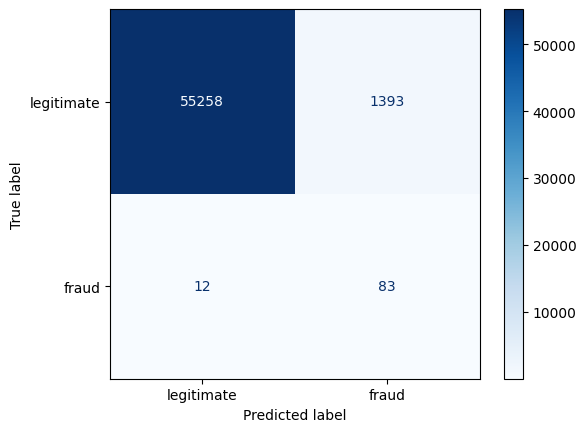

In [66]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["legitimate", "fraud"])
disp.plot(cmap="Blues")
plt.show()

In [67]:
logistic_results = {
    "Model": "Logistic Regression",
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob)
}

print(logistic_results)

{'Model': 'Logistic Regression', 'Precision': 0.05623306233062331, 'Recall': 0.8736842105263158, 'F1-score': 0.10566518141311267, 'ROC-AUC': np.float64(0.9658392242808925), 'Average Precision': np.float64(0.6719353631354262)}


In [69]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    max_depth=12,
    min_samples_split=2,
    min_samples_leaf=2,
    n_jobs=-1
)

In [70]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=12,
                       min_samples_leaf=2, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [71]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:,1]

In [81]:
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.88      0.73      0.80        95

    accuracy                           1.00     56746
   macro avg       0.94      0.86      0.90     56746
weighted avg       1.00      1.00      1.00     56746



In [72]:
precision_score(y_test, rf_pred)

0.8846153846153846

In [74]:
recall_score(y_test, rf_pred)

0.7263157894736842

In [75]:
f1_score(y_test, rf_pred)

0.7976878612716763

In [77]:
roc_auc_score(y_test, rf_prob)

np.float64(0.9748684698277263)

In [78]:
average_precision_score(y_test, rf_prob)

np.float64(0.8055122931735378)

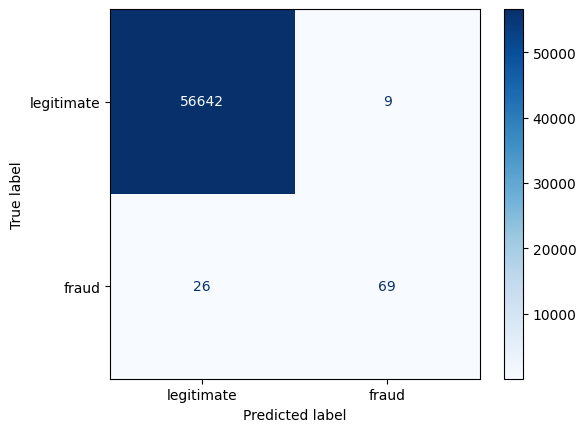

In [93]:
cm_rf = confusion_matrix(y_test, rf_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["legitimate", "fraud"])
disp.plot(cmap="Blues")
plt.show()

In [80]:
rf_results = {
    "Model": "Random Forest",
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1-score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_prob),
    "Average Precision": average_precision_score(y_test, rf_prob)
}

comparison_df = pd.DataFrame([
    logistic_results,
    rf_results
]).set_index("Model")

display(comparison_df.round(4))

,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,
Logistic Regression,0.0562,0.8737,0.1057,0.9658,0.6719
Random Forest,0.8846,0.7263,0.7977,0.9749,0.8055


In [82]:
!pip install -q xgboost

In [83]:
from xgboost import XGBClassifier

In [84]:
xgb_model = XGBClassifier(
    scale_pos_weight = scale_pos_weight,
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    n_jobs=-1,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="aucpr",
    tree_method="hist"
)

In [85]:
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)

In [86]:
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:,1]

In [87]:
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.66      0.82      0.73        95

    accuracy                           1.00     56746
   macro avg       0.83      0.91      0.86     56746
weighted avg       1.00      1.00      1.00     56746



In [88]:
precision_score(y_test, xgb_pred)

0.6554621848739496

In [89]:
f1_score(y_test, xgb_pred)

0.7289719626168224

In [90]:
recall_score(y_test, xgb_pred)

0.8210526315789474

In [91]:
roc_auc_score(y_test, xgb_prob)

np.float64(0.9702044559068497)

In [92]:
average_precision_score(y_test, xgb_prob)

np.float64(0.8119078160060865)

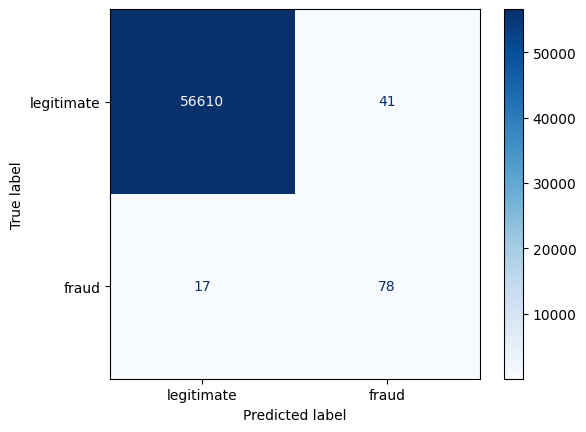

In [94]:
cm_xgb=confusion_matrix(y_test, xgb_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=["legitimate", "fraud"])
disp.plot(cmap="Blues")
plt.show()

In [95]:
xgb_results = {
    "Model": "XGBoost",
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1-score": f1_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob),
    "Average Precision": average_precision_score(y_test, xgb_prob)
}

comparison_df = pd.DataFrame([
    logistic_results,
    rf_results,
    xgb_results
])

display(
    comparison_df.set_index("Model").round(4)
)

,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,
Logistic Regression,0.0562,0.8737,0.1057,0.9658,0.6719
Random Forest,0.8846,0.7263,0.7977,0.9749,0.8055
XGBoost,0.6555,0.8211,0.7290,0.9702,0.8119
